# Module 1 · Enzymes and Reaction Kinetics
**25 minutes: principles 7 · SBPase example 5 · FBPase exercises 10 · discussion 3**

[Course introduction](00_Introduction.ipynb)

**Learning objectives:** use the worked SBPase example to implement a different enzyme,
FBPase; run controlled Vmax experiments; distinguish reaction flux from net assimilation.

[Reference answers with runnable code](#reference-answer) are included at the end.


In [ ]:
# Locate c3_model for both local Jupyter and Kaggle sessions.
import sys
from pathlib import Path

_model_root = None
for _candidate in (Path.cwd(), *Path.cwd().parents):
    if (_candidate / "c3_model" / "__init__.py").is_file():
        _model_root = _candidate
        break

if _model_root is None:
    _matches = sorted(Path("/kaggle/input").glob("**/c3_model/__init__.py"))
    if _matches:
        _model_root = _matches[0].parent.parent

if _model_root is None:
    raise FileNotFoundError(
        "Cannot find c3_model/__init__.py. On Kaggle, add the dataset containing "
        "the complete c3_model folder via Add Input. Locally, start Jupyter "
        "from the project folder or its Course subfolder."
    )

if str(_model_root) not in sys.path:
    sys.path.insert(0, str(_model_root))
print("c3_model directory:", _model_root / "c3_model")


## 1. Principles · 7 min
At fixed catalytic turnover, enzyme abundance determines maximum reaction capacity:
$$V_{\max}=k_{cat}[E].$$
For a simple irreversible single-substrate reaction,
$$v=V_{\max}\frac{S}{K_m+S}.$$
At $S=K_m$, the rate is half the maximum. Increasing enzyme abundance increases Vmax,
but substrate supply, products, energy and other reactions may constrain the realized flux.

SBPase converts SBP to S7P and phosphate. The supplied rate law is
$$v_9=V_{\max}\frac{[SBP]-[Pi][S7P]/K_{eq}}{[SBP]+K_m(1+[Pi]/K_i)}.$$
The reverse term reduces the net forward driving force. At fixed Pi, a smaller Ki gives
stronger inhibition. Omitting these terms changes the model rather than merely simplifying
the Python syntax. Concentrations are in mM and this function returns mM s⁻¹.

`enzyme_factors={'SBPase': 1.5}` increases SBPase capacity by 50% at fixed kcat.
This intervention is applied after initialization, so the initial metabolite and phosphate
pools remain the same. In the worked example, vary SBPase abundance or its rate equation. In the exercise,
transfer the same method to FBPase. Keep environmental inputs and other capacities fixed.


## 2. Worked example · SBPase · 5 min
**Change only `sbpase_amount`, then run the cell.**

| Value | Meaning |
|---|---|
| `1.0` | Baseline SBPase abundance |
| `1.5` | 50% more SBPase; 1.5× Vmax at fixed kcat |
| `2.0` | Twice the SBPase abundance and Vmax |

The supplied SBPase function is used in both treatments. The plots compare
**Baseline (1×)** with **SBPase at your chosen abundance**. Both treatments start from
the same preconditioned state, with the same environment and other enzyme capacities.
At `sbpase_amount = 1.0`, the two curves overlap. Other values change the treatment's
Vmax while the model computes the resulting flux and net assimilation.

Read the provided Python rate equation as an example. In the next section, you will
write the FBPase rate equation yourself using the supplied mathematical formula.


SBPase abundance: baseline=1.0×; treatment=1.5×
Net A at 600 s: baseline=15.5582; treatment=16.4570 µmol CO₂ m⁻² s⁻¹
SBPase v9 at 600 s: baseline=8.1088; treatment=8.5488 µmol m⁻² s⁻¹
+50% SBPase capacity gives +5.78% net A in this simulation.


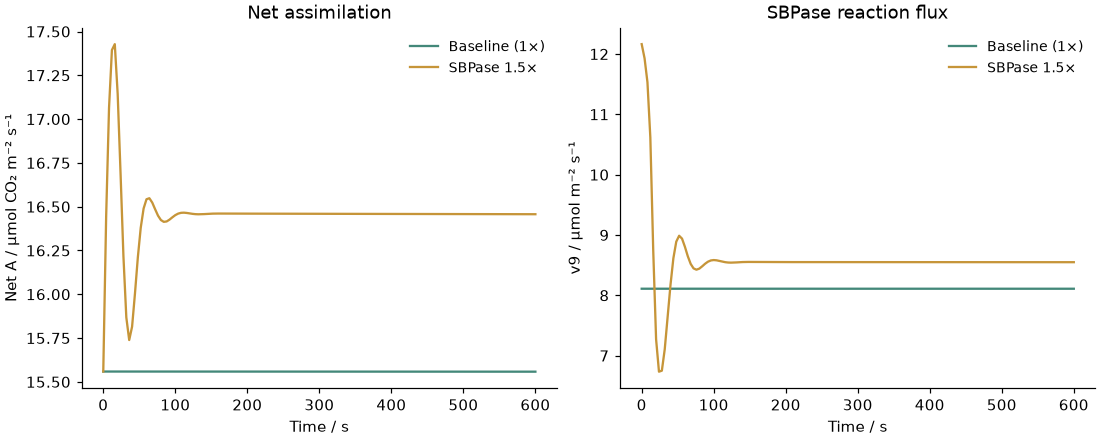

In [ ]:
from c3_model import C3Model, simulate
from c3_model.plots import style
import matplotlib.pyplot as plt
style()

sbpase_amount = 1.5  # CHANGE ONLY THIS VALUE: 1.0, 1.5, 2.0, etc.

# Provided SBPase equation: no editing is needed for this demonstration.
def sbpase_rate(vmax, sbp, pi, s7p, keq, km, ki):
    numerator = sbp - pi * s7p / keq
    denominator = sbp + km * (1 + pi / ki)
    return vmax * numerator / denominator

warm = simulate(C3Model(sbpase_rate=sbpase_rate), 3000).states[-1]
base = simulate(C3Model(sbpase_rate=sbpase_rate), 600, initial=warm)
changed = simulate(C3Model(sbpase_rate=sbpase_rate,
                          enzyme_factors={'SBPase': sbpase_amount}), 600, initial=warm)

print(f'SBPase abundance: baseline=1.0×; treatment={sbpase_amount:g}×')
print(f'Net A at 600 s: baseline={base.assimilation[-1]:.4f}; treatment={changed.assimilation[-1]:.4f} µmol CO₂ m⁻² s⁻¹')
print(f'SBPase v9 at 600 s: baseline={base.flux("v9")[-1]:.4f}; treatment={changed.flux("v9")[-1]:.4f} µmol m⁻² s⁻¹')
percent = (changed.assimilation[-1] / base.assimilation[-1] - 1) * 100
print(f'{(sbpase_amount-1)*100:+.0f}% SBPase capacity gives {percent:+.2f}% net A in this simulation.')

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for run, label, color in [(base, 'Baseline (1×)', '#438879'),
                          (changed, f'SBPase {sbpase_amount:g}×', '#c69539')]:
    axes[0].plot(run.time, run.assimilation, label=label, color=color)
    axes[1].plot(run.time, run.flux('v9'), label=label, color=color)
axes[0].set(xlabel='Time / s', ylabel='Net A / µmol CO₂ m⁻² s⁻¹', title='Net assimilation')
axes[1].set(xlabel='Time / s', ylabel='v9 / µmol m⁻² s⁻¹', title='SBPase reaction flux')
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
plt.show()


## 3. Transfer exercise · FBPase · 10 min
The SBPase example above is complete. Now implement a different enzyme using its formula.
**FBPase:** FBP + H₂O → F6P + Pi; this reaction is recorded as **v6** in the model.

### FBPase rate equation

```text
v6 = Vmax × (FBP − F6P × Pi / Keq)
          / (FBP + Km × (1 + F6P/Ki_F6P + Pi/Ki_Pi))
```

FBPase has both F6P and Pi inhibition in the denominator. Use the variables
`fbp`, `f6p`, `pi`, `keq`, `km`, `ki_f6p` and `ki_pi` from the function signature.

| Isolated-assay input | Value | Unit |
|---|---:|---|
| FBP | 0.2 | mM |
| F6P | 0.1 | mM |
| Pi | 1.0 | mM |
| Keq, in the source's concentration convention | 6.66 × 10⁵ | mM |
| Km | 0.033 | mM |
| Ki,F6P | 0.7 | mM |
| Ki,Pi | 12.0 | mM |
| Vmax | 0.25, 0.5, 1.0 | mM s⁻¹ |

These values retain the supplied model's kinetics. The assay concentrations are fixed
teaching inputs; the full network computes its own metabolite concentrations.

**1A · Write the new rate equation (3 min).** Fill in `numerator` and `denominator`
in `student_fbpase`. Keep the reverse term and both inhibitor terms. Your function
should return approximately **0.415862 mM/s** at Vmax = 0.5 and the assay inputs above.

**1B · Design a Vmax experiment (3 min).** Write a loop or list comprehension for
`assay_rates`, calling your function at each value in `vmax_values`. Keep all other
inputs fixed. Plot the results using the supplied plotting code and explain the slope.
For an additional check, compare Ki,Pi = 12 and 6 mM at Vmax = 0.5.

**1C · Compare enzyme amounts (4 min).** In the separate amount-experiment cell,
change `fbpase_amount` and run it. Record the actual capacity ratio, net A and v6.
Compare 0.5×, 1× and 2×. Explain why the isolated assay is proportional to Vmax
while whole-network assimilation need not be. The parameter experiment remains
runnable while you are still completing the formula and assay exercises.

Run the model-location cell first. This exercise cell imports its own dependencies;
complete the three TODOs and rerun it. Use the accompanying updated `c3_model` folder
and restart the kernel once after replacing the source files.


In [ ]:
from c3_model import C3Model, simulate
from c3_model.plots import style
import numpy as np
import matplotlib.pyplot as plt
style()

def student_fbpase(vmax, fbp, pi, f6p, keq, km, ki_f6p, ki_pi):
    numerator = None    # TODO 1A: write the numerator from the FBPase equation
    denominator = None  # TODO 1A: include both F6P and Pi inhibition
    if numerator is None or denominator is None:
        return None
    return vmax * numerator / denominator

vmax_values = np.array([0.25, 0.5, 1.0])  # mM/s for the isolated-enzyme assay
assay_rates = None  # TODO 1B: call student_fbpase once for each Vmax; return a list
# Assay inputs: fbp=0.2, pi=1.0, f6p=0.1, keq=6.66e5, km=0.033,
#               ki_f6p=0.7 and ki_pi=12.0. Keep these fixed while changing Vmax.

probe = student_fbpase(0.5, 0.2, 1.0, 0.1, 6.66e5, 0.033, 0.7, 12.0)
if probe is None:
    print('Complete the two formula lines in 1A, then run this cell again.')
elif assay_rates is None:
    print(f'Your function returns {probe:.6f} mM/s at the reference assay inputs.')
    print('Complete assay_rates in 1B using a loop or a list comprehension, then rerun.')
else:
    np.testing.assert_allclose(probe, 0.41586185918578616, rtol=1e-8)
    assay_rates = np.asarray(assay_rates, dtype=float)
    assert assay_rates.shape == vmax_values.shape, 'Return one rate per Vmax.'
    np.testing.assert_allclose(assay_rates / assay_rates[1], vmax_values / vmax_values[1])
    print('Vmax values / mM/s:', vmax_values)
    print('Isolated FBPase rates / mM/s:', assay_rates)
    fig, ax = plt.subplots(figsize=(6, 3.6), constrained_layout=True)
    ax.plot(vmax_values, assay_rates, 'o-', color='#6774b8')
    ax.set(xlabel='Vmax / mM s⁻¹', ylabel='Isolated v6 / mM s⁻¹', title='Fixed-concentration FBPase assay')
    plt.show()


Complete the two formula lines in 1A, then run this cell again.


### 1C · Run the amount experiment
**Change `fbpase_amount` in the next cell, then press Shift+Enter.**
This cell runs even if the formula or Vmax-sweep exercise is unfinished. It uses the
supplied model equation until `student_fbpase` returns a completed rate; after that,
both treatments use your function. The output states which equation is active.

`fbpase_amount` changes the network's FBPase capacity. `vmax_values` in the preceding
cell changes only the isolated assay. Every run recomputes both network treatments.
At 1.0× the curves should overlap. Other amounts can give small assimilation responses
because the network is limited by several processes. Read the numeric differences
and the labelled late-time flux inset as well as the full curves.


FBPase rate law: supplied model equation
fbpase_amount=1.5; verified capacity ratio=1.5×
Output at 600 s                 Baseline       Treatment       Difference
Net A / µmol CO₂ m⁻² s⁻¹       15.558156      15.623540      +0.065384 (+0.420%)
v6 / µmol m⁻² s⁻¹              9.784669       9.834795      +0.050126 (+0.512%)
The amount experiment is active. Complete the formula exercise to use your own equation.


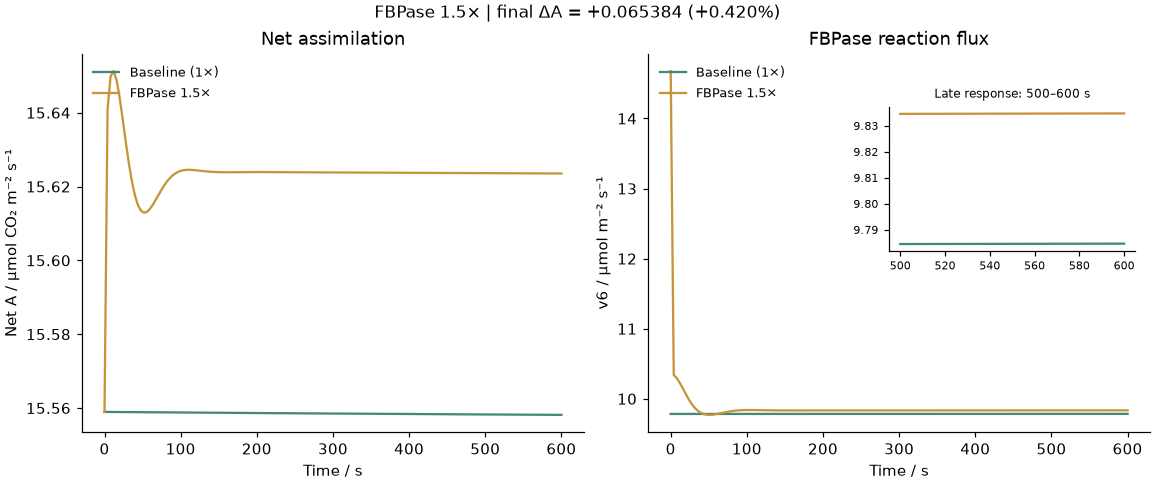

In [ ]:
from c3_model import C3Model, simulate
from c3_model.plots import style
import inspect
import numpy as np
import matplotlib.pyplot as plt
style()

fbpase_amount = 1.5  # CHANGE THIS VALUE, THEN RUN THIS CELL (Shift+Enter)

# The amount experiment always runs, even before the formula exercise is complete.
rate_function = locals().get('student_fbpase')
rate_options = {}
rate_label = 'supplied model equation'
if callable(rate_function):
    reference_probe = rate_function(0.5, 0.2, 1.0, 0.1, 6.66e5, 0.033, 0.7, 12.0)
    if reference_probe is not None:
        if not np.isfinite(reference_probe) or reference_probe <= 0:
            raise ValueError('Check your FBPase equation: the reference assay must give a positive finite rate.')
        double_probe = rate_function(1.0, 0.2, 1.0, 0.1, 6.66e5, 0.033, 0.7, 12.0)
        np.testing.assert_allclose(double_probe, 2 * reference_probe, rtol=1e-10,
            err_msg='Use the vmax argument in your equation; do not replace it with a fixed number.')
        if 'fbpase_rate' not in inspect.signature(C3Model).parameters:
            raise RuntimeError('Use the updated c3_model folder and restart the kernel.')
        rate_options = {'fbpase_rate': rate_function}
        rate_label = 'your student_fbpase equation'

# Always recompute from a common, unmodified preconditioned state.
warm = simulate(C3Model(), 3000).states[-1]
baseline_model = C3Model(**rate_options)
treatment_model = C3Model(enzyme_factors={'FBPase': fbpase_amount}, **rate_options)
applied_ratio = float(treatment_model.equations.V6 / baseline_model.equations.V6)
np.testing.assert_allclose(applied_ratio, fbpase_amount)
base = simulate(baseline_model, 600, initial=warm)
changed = simulate(treatment_model, 600, initial=warm)
delta_a = float(changed.assimilation[-1] - base.assimilation[-1])
delta_v6 = float(changed.flux('v6')[-1] - base.flux('v6')[-1])
percent_a = 100 * delta_a / base.assimilation[-1]
percent_v6 = 100 * delta_v6 / base.flux('v6')[-1]
print(f'FBPase rate law: {rate_label}')
print(f'fbpase_amount={fbpase_amount:g}; verified capacity ratio={applied_ratio:g}×')
print('Output at 600 s                 Baseline       Treatment       Difference')
print(f'Net A / µmol CO₂ m⁻² s⁻¹    {base.assimilation[-1]:12.6f} {changed.assimilation[-1]:14.6f} {delta_a:+14.6f} ({percent_a:+.3f}%)')
print(f'v6 / µmol m⁻² s⁻¹          {base.flux("v6")[-1]:12.6f} {changed.flux("v6")[-1]:14.6f} {delta_v6:+14.6f} ({percent_v6:+.3f}%)')
if not rate_options:
    print('The amount experiment is active. Complete the formula exercise to use your own equation.')

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), constrained_layout=True)
for run, label, color in [(base, 'Baseline (1×)', '#438879'),
                          (changed, f'FBPase {fbpase_amount:g}×', '#c69539')]:
    axes[0].plot(run.time, run.assimilation, label=label, color=color)
    axes[1].plot(run.time, run.flux('v6'), label=label, color=color)
axes[0].set(xlabel='Time / s', ylabel='Net A / µmol CO₂ m⁻² s⁻¹', title='Net assimilation')
axes[1].set(xlabel='Time / s', ylabel='v6 / µmol m⁻² s⁻¹', title='FBPase reaction flux')
for ax in axes:
    ax.legend(frameon=False, fontsize=8.5, loc='upper left')
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
# A labelled late-time inset makes a small true flux response visible.
zoom = axes[1].inset_axes([0.48, 0.48, 0.49, 0.38])
for run, color in [(base, '#438879'), (changed, '#c69539')]:
    late = run.time >= 500
    zoom.plot(run.time[late], run.flux('v6')[late], color=color)
zoom.set_title('Late response: 500–600 s', fontsize=8)
zoom.tick_params(labelsize=7)
zoom.ticklabel_format(axis='y', style='plain', useOffset=False)
fig.suptitle(f'FBPase {fbpase_amount:g}× | final ΔA = {delta_a:+.6f} ({percent_a:+.3f}%)', fontsize=11)
plt.show()


## 4. Solutions and discussion · 3 min
[Review the FBPase reference answers below](#reference-answer) after completing your code.
State what you wrote yourself: the new rate law and the Vmax sweep. The plotting and
integration code is supplied so you can focus on translating the equation and designing
controlled comparisons. Continue to [Module 2](02_Metabolic_Networks.ipynb).


<a id="reference-answer"></a>
## Reference answers 1A–1C · FBPase
**1A.** Translate the supplied FBPase equation into a numerator and denominator.
Include the reverse term and **both** F6P and Pi inhibition. The calculation gives
approximately 0.415862 mM/s at the reference assay inputs.

**1B.** Call the function once per Vmax using a loop or list comprehension. At fixed
substrate, product and inhibitor concentrations, the remaining fraction is constant,
so doubling Vmax doubles the isolated-enzyme rate. Reducing Ki,Pi strengthens Pi
inhibition and lowers the rate for these positive-forward assay conditions.

**1C.** The independent amount cell always recomputes baseline and treatment results.
It reports the applied Vmax ratio and final changes in net assimilation and v6. With
the supplied kinetics, 1.5× FBPase gives about +0.42% net A in this environment.
A larger capacity change does not require a proportional assimilation change.

The reference answer uses the amount selected in the experiment above (or 1.5×
when run independently). Its function and variables are local, so it preserves your
exercise code and parameter choice. The late-time inset magnifies the actual flux
values without changing the model equations.


Vmax values / mM/s: [0.25 0.5  1.  ]
Isolated FBPase rates / mM/s: [0.20793093 0.41586186 0.83172372]
FBPase rate law: your student_fbpase equation
fbpase_amount=1.5; verified capacity ratio=1.5×
Output at 600 s                 Baseline       Treatment       Difference
Net A / µmol CO₂ m⁻² s⁻¹       15.558156      15.623540      +0.065384 (+0.420%)
v6 / µmol m⁻² s⁻¹              9.784669       9.834795      +0.050126 (+0.512%)


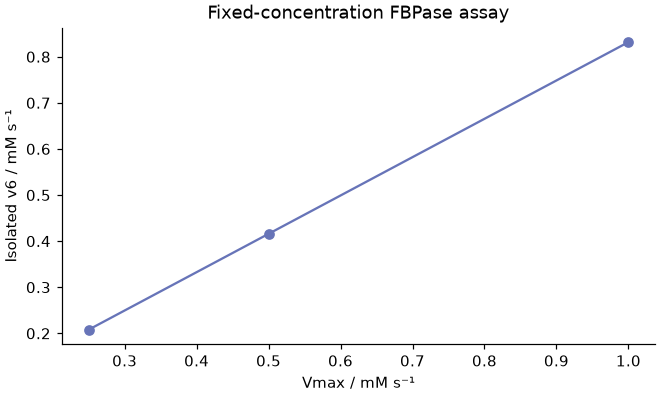

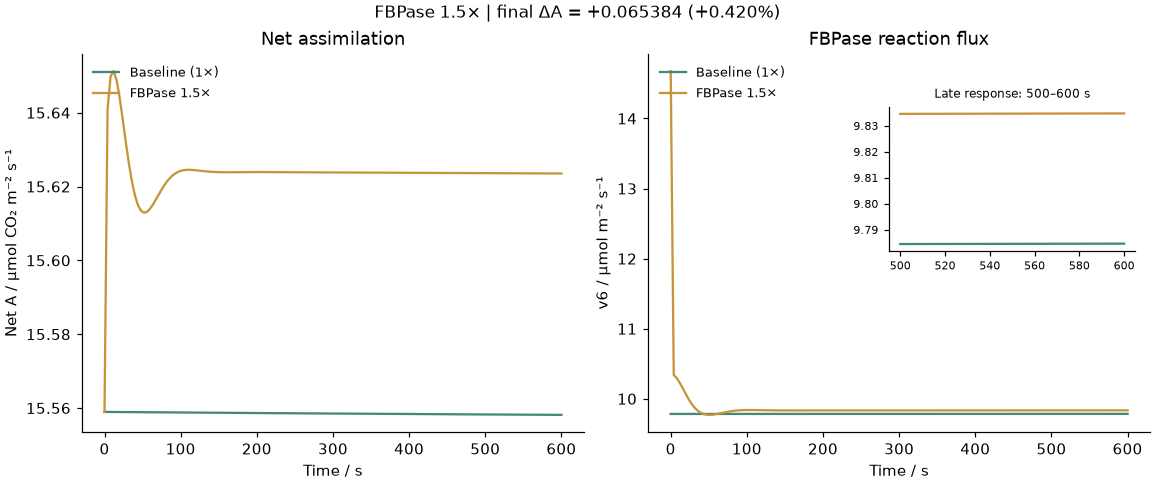

In [ ]:
def _run_fbpase_reference(selected_amount):
    from c3_model import C3Model, simulate
    from c3_model.plots import style
    import numpy as np
    import matplotlib.pyplot as plt
    style()

    def student_fbpase(vmax, fbp, pi, f6p, keq, km, ki_f6p, ki_pi):
        numerator = fbp - f6p * pi / keq
        denominator = fbp + km * (1 + f6p / ki_f6p + pi / ki_pi)
        return vmax * numerator / denominator

    vmax_values = np.array([0.25, 0.5, 1.0])  # mM/s for the isolated-enzyme assay
    assay_rates = [student_fbpase(v, 0.2, 1.0, 0.1, 6.66e5, 0.033, 0.7, 12.0) for v in vmax_values]
    # Assay inputs: fbp=0.2, pi=1.0, f6p=0.1, keq=6.66e5, km=0.033,
    #               ki_f6p=0.7 and ki_pi=12.0. Keep these fixed while changing Vmax.

    probe = student_fbpase(0.5, 0.2, 1.0, 0.1, 6.66e5, 0.033, 0.7, 12.0)
    if probe is None:
        print('Complete the two formula lines in 1A, then run this cell again.')
    elif assay_rates is None:
        print(f'Your function returns {probe:.6f} mM/s at the reference assay inputs.')
        print('Complete assay_rates in 1B using a loop or a list comprehension, then rerun.')
    else:
        np.testing.assert_allclose(probe, 0.41586185918578616, rtol=1e-8)
        assay_rates = np.asarray(assay_rates, dtype=float)
        assert assay_rates.shape == vmax_values.shape, 'Return one rate per Vmax.'
        np.testing.assert_allclose(assay_rates / assay_rates[1], vmax_values / vmax_values[1])
        print('Vmax values / mM/s:', vmax_values)
        print('Isolated FBPase rates / mM/s:', assay_rates)
        fig, ax = plt.subplots(figsize=(6, 3.6), constrained_layout=True)
        ax.plot(vmax_values, assay_rates, 'o-', color='#6774b8')
        ax.set(xlabel='Vmax / mM s⁻¹', ylabel='Isolated v6 / mM s⁻¹', title='Fixed-concentration FBPase assay')
        plt.show()

    from c3_model import C3Model, simulate
    from c3_model.plots import style
    import inspect
    import numpy as np
    import matplotlib.pyplot as plt
    style()

    fbpase_amount = selected_amount

    # The amount experiment always runs, even before the formula exercise is complete.
    rate_function = locals().get('student_fbpase')
    rate_options = {}
    rate_label = 'supplied model equation'
    if callable(rate_function):
        reference_probe = rate_function(0.5, 0.2, 1.0, 0.1, 6.66e5, 0.033, 0.7, 12.0)
        if reference_probe is not None:
            if not np.isfinite(reference_probe) or reference_probe <= 0:
                raise ValueError('Check your FBPase equation: the reference assay must give a positive finite rate.')
            double_probe = rate_function(1.0, 0.2, 1.0, 0.1, 6.66e5, 0.033, 0.7, 12.0)
            np.testing.assert_allclose(double_probe, 2 * reference_probe, rtol=1e-10,
                err_msg='Use the vmax argument in your equation; do not replace it with a fixed number.')
            if 'fbpase_rate' not in inspect.signature(C3Model).parameters:
                raise RuntimeError('Use the updated c3_model folder and restart the kernel.')
            rate_options = {'fbpase_rate': rate_function}
            rate_label = 'your student_fbpase equation'

    # Always recompute from a common, unmodified preconditioned state.
    warm = simulate(C3Model(), 3000).states[-1]
    baseline_model = C3Model(**rate_options)
    treatment_model = C3Model(enzyme_factors={'FBPase': fbpase_amount}, **rate_options)
    applied_ratio = float(treatment_model.equations.V6 / baseline_model.equations.V6)
    np.testing.assert_allclose(applied_ratio, fbpase_amount)
    base = simulate(baseline_model, 600, initial=warm)
    changed = simulate(treatment_model, 600, initial=warm)
    delta_a = float(changed.assimilation[-1] - base.assimilation[-1])
    delta_v6 = float(changed.flux('v6')[-1] - base.flux('v6')[-1])
    percent_a = 100 * delta_a / base.assimilation[-1]
    percent_v6 = 100 * delta_v6 / base.flux('v6')[-1]
    print(f'FBPase rate law: {rate_label}')
    print(f'fbpase_amount={fbpase_amount:g}; verified capacity ratio={applied_ratio:g}×')
    print('Output at 600 s                 Baseline       Treatment       Difference')
    print(f'Net A / µmol CO₂ m⁻² s⁻¹    {base.assimilation[-1]:12.6f} {changed.assimilation[-1]:14.6f} {delta_a:+14.6f} ({percent_a:+.3f}%)')
    print(f'v6 / µmol m⁻² s⁻¹          {base.flux("v6")[-1]:12.6f} {changed.flux("v6")[-1]:14.6f} {delta_v6:+14.6f} ({percent_v6:+.3f}%)')
    if not rate_options:
        print('The amount experiment is active. Complete the formula exercise to use your own equation.')

    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), constrained_layout=True)
    for run, label, color in [(base, 'Baseline (1×)', '#438879'),
                              (changed, f'FBPase {fbpase_amount:g}×', '#c69539')]:
        axes[0].plot(run.time, run.assimilation, label=label, color=color)
        axes[1].plot(run.time, run.flux('v6'), label=label, color=color)
    axes[0].set(xlabel='Time / s', ylabel='Net A / µmol CO₂ m⁻² s⁻¹', title='Net assimilation')
    axes[1].set(xlabel='Time / s', ylabel='v6 / µmol m⁻² s⁻¹', title='FBPase reaction flux')
    for ax in axes:
        ax.legend(frameon=False, fontsize=8.5, loc='upper left')
        ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    # A labelled late-time inset makes a small true flux response visible.
    zoom = axes[1].inset_axes([0.48, 0.48, 0.49, 0.38])
    for run, color in [(base, '#438879'), (changed, '#c69539')]:
        late = run.time >= 500
        zoom.plot(run.time[late], run.flux('v6')[late], color=color)
    zoom.set_title('Late response: 500–600 s', fontsize=8)
    zoom.tick_params(labelsize=7)
    zoom.ticklabel_format(axis='y', style='plain', useOffset=False)
    fig.suptitle(f'FBPase {fbpase_amount:g}× | final ΔA = {delta_a:+.6f} ({percent_a:+.3f}%)', fontsize=11)
    plt.show()

_run_fbpase_reference(globals().get('fbpase_amount', 1.5))
